# Flat integral stringers, simply supported and clamped: the Caltech shells AS-2 to AS-4 (Singer, Arbocz and Babcock 1971)

Singer, Arbocz and Babcock [1] tested in axial compression, besides
ring-stiffened shells, three aluminium shells with 80 integral stringers
machined on the outside, AS-2, AS-3 and AS-4. Their stringers are flat (3.5
to 6 times wider than tall), and the paper gives for them the buckling
loads of a linear smeared-stiffener theory for two end conditions: simple
support SS-3 ($w = v = N_x = M_x = 0$) and clamping C-4 ($w = v = u =
w_{,x} = 0$), the latter with a membrane pre-buckling state and with the
nonlinear pre-buckling deformation caused by the end rings (Table 2, p.
71). The authors judged the end rings of their test rig rigid enough to
consider the shells clamped (p. 72): clamping raises the load of these
shells by 23 to 48 %.

This notebook builds the shells as `MultiDomain` assemblies with one plate
strip ("blade") per stringer and compares with every published value. The
torsion constant $J$ of the stringers is not printed in [1]; it enters the
smeared theory through the twisting term $G J w_{,xy}^2/d$ and the discrete
model through the twisting stiffness of the blades, and it has a large
effect on the clamped shells, whose buckles are short. Instead of choosing a
value, the notebook runs a **sensitivity study** over $J$, from $J = 0$ to the
Saint-Venant constant $J_r$ of the rectangle that reproduces the stringer
area, moment of inertia and eccentricity of Table 1.

[1] J. Singer, J. Arbocz and C. D. Babcock Jr., *Buckling of imperfect
stiffened cylindrical shells under axial compression*, AIAA J. 9(1),
68-75, 1971, doi:10.2514/3.6125.

[2] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

[3] M. F. Card and R. M. Jones, *Experimental and theoretical results for
buckling of eccentrically stiffened cylinders*, NASA TN D-3639, 1966,
https://ntrs.nasa.gov/citations/19660027866.

[4] J. Singer, M. Baruch and O. Harari, *On the stability of eccentrically
stiffened cylindrical shells under axial compression*, Int. J. Solids
Struct. 3(4), 445-470, 1967, doi:10.1016/0020-7683(67)90001-7 (the
smeared theory of the SS-3 loads of [1]; cited through [1], not read).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
import stringer_cylinder_utils as su


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))


def plot_mode(ax, md_, c, skin, R, title, ns, frac=1.):
    x, th, w = bu.skin_w(md_, c, skin, R)
    sel = th <= frac*th.max() + 1e-12
    ax.pcolormesh(np.degrees(th[sel]), x, (w[sel]/np.abs(w).max()).T, cmap='RdBu_r',
                  shading='auto', vmin=-1, vmax=1)
    pos = (np.arange(ns) + 0.5)*2*np.pi/ns
    pos = pos[pos <= th[sel].max()]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')

## Shells, geometry and material

Table 1 of [1] (p. 71), all dimensions in inches: skin thickness $t$, $R/t$,
$L/R$, the stringer area $A/(dt)$, eccentricity $-e/t$ (positive here: the
stringers are outside, Fig. 2), moment of inertia about the stringer
centroid $I/(dt^3)$, spacing $d$, length $L$ and number of stringers; $E =
10 \times 10^6$ psi, $\nu = 0.3$ (footnote). The skin thickness is the one
obtained by weighing, an average, since the cutter leaves a skin surface of
straight lines between the stringers; "the stiffeners are not rectangular in
all cases and the measured shape is used in the calculation of stiffener
properties" (p. 71).

Table 2 of [1] (p. 71), lb/in: SS-3, the classical linear (smeared) theory
[4]; C-4 with the membrane pre-buckling state; C-4 with the nonlinear
pre-buckling deformation caused by the end rings; the test; and the ratio of
test to the nonlinear C-4 value. The paper does not say which program gave
the C-4 values (it names the BOSOR program among the available tools, p.
69). The linear analysis gives one axial half-wave and 9 or 10
circumferential waves for SS-3, and the clamped analysis 10 or more
circumferential waves and a few axial half-waves (p. 72).

**Units and the inputs used.** in, lb, psi; $\bar{N} = P/(2\pi R)$ in lb/in.
$R = (R/t)\, t$ (4.000 to 4.002 in) and $L = 5.50$ in as printed ($(L/R) R
= 5.52$ in). The printed spacing $d = 0.316$ in is 0.5 % above $2\pi R/80
= 0.3143$ in; the smeared theory needs only the stiffnesses per unit
circumference $A/d$, $I/d$, which follow from Table 1 independently of $d$,
and the discrete model takes 80 stringers with the area $A = (A/dt)\, t\,
2\pi R/80$, so that both carry the same stiffness per unit circumference.

**Stringer section.** A rectangle $t_s \times h_s$ (width $\times$ height)
standing on the skin has $I = t_s h_s^3/12$: $h_s = \sqrt{12 I/A}$ and $t_s =
A/h_s$ reproduce $e = (t + h_s)/2$ of Table 1 within 0.7 %, and the
stringers come out 0.066 in wide and 0.011 to 0.019 in tall. Their
Saint-Venant torsion constant (rectangle, $J_r = c^3 a\,[1/3 - 64 c/(\pi^5 a)
\tanh(\pi a/(2c))]$, $a \ge c$ the sides) is the upper reference of the
sensitivity study.

In [2]:
E, NU = 10e6, 0.3  # psi, Table 1 of [1]
G = E/(2*(1 + NU))
NS = 80
L = 5.50  # in
# Table 1 of [1], p. 71: t (in), R/t, L/R, A/(dt), -e/t, I/(dt^3)
TABLE1 = {'AS-2': (7.74e-3, 517, 1.38, 0.506, 1.72, 0.2466),
          'AS-3': (11.05e-3, 362, 1.38, 0.330, 1.29, 0.0679),
          'AS-4': (10.21e-3, 392, 1.38, 0.235, 1.07, 0.0248)}
# Table 2 of [1], p. 71 (lb/in): SS-3, C-4 membrane, C-4 nonlinear, test, ratio
TABLE2 = {'AS-2': (123.8, 183.8, 185.6, 129.2, 0.697),
          'AS-3': (219.8, 290.2, 285.7, 200.3, 0.703),
          'AS-4': (173.5, 213.9, 208.1, 152.0, 0.731)}
PUB = ['SS-3', 'C-4 membrane', 'C-4 nonlinear', 'test']


def rect_J(a, c):
    # Saint-Venant torsion constant of a rectangle a x c
    a, c = max(a, c), min(a, c)
    return c**3*a*(1/3 - 64/np.pi**5*c/a*np.tanh(np.pi*a/(2*c)))


shells = {}
rows = []
for s, (t, Rt, LR, Ab, e, Ib) in TABLE1.items():
    R = Rt*t
    d = 2*np.pi*R/NS
    A, I, z = Ab*d*t, Ib*d*t**3, e*t
    hs = np.sqrt(12*I/A)
    ts = A/hs
    Hs = hs + t/2
    sh = dict(t=t, R=R, d=d, A=A, I=I, z=z, hs=hs, ts=ts, Hs=Hs, Jr=rect_J(ts, hs), Jp=Hs*ts**3/3)
    shells[s] = sh
    rows.append([s, '%.5f' % t, '%.4f' % R, '%.3f' % (LR*R), '%.4f' % d, '%.5f' % ts, '%.5f' % hs,
                 '%.2f' % (ts/hs), '%.5f (%.5f, %+.1f %%)' % ((t + hs)/2, z, pct((t + hs)/2, z)),
                 '%.3e' % sh['Jr'], '%.3e' % sh['Jp'], '%.4f' % (sh['Jr']/sh['Jp'])])
table(['shell', 't, in', 'R, in', '(L/R) R, in', '2 pi R/80, in', 't_s, in', 'h_s, in', 't_s/h_s',
       '(t + h_s)/2 (e of [1]), in', 'J_r, in^4', 'J of the strip, in^4', 'J_r/J_strip'], rows)
rows = [[s] + list(v) + ['%.3f' % (v[3]/v[2])] for s, v in TABLE2.items()]
table(['shell', 'SS-3', 'C-4 membrane', 'C-4 nonlinear', 'test', 'ratio of [1]', 'test/C-4 nonlinear'], rows)

| shell | t, in | R, in | (L/R) R, in | 2 pi R/80, in | t_s, in | h_s, in | t_s/h_s | (t + h_s)/2 (e of [1]), in | J_r, in^4 | J of the strip, in^4 | J_r/J_strip |
|---|---|---|---|---|---|---|---|---|---|---|---|
| AS-2 | 0.00774 | 4.0016 | 5.522 | 0.3143 | 0.06576 | 0.01872 | 3.51 | 0.01323 (0.01331, -0.6 %) | 1.181e-07 | 2.141e-06 | 0.0551 |
| AS-3 | 0.01105 | 4.0001 | 5.520 | 0.3142 | 0.06598 | 0.01736 | 3.80 | 0.01421 (0.01425, -0.3 %) | 9.612e-08 | 2.191e-06 | 0.0439 |
| AS-4 | 0.01021 | 4.0023 | 5.523 | 0.3143 | 0.06564 | 0.01149 | 5.71 | 0.01085 (0.01092, -0.7 %) | 2.954e-08 | 1.565e-06 | 0.0189 |

| shell | SS-3 | C-4 membrane | C-4 nonlinear | test | ratio of [1] | test/C-4 nonlinear |
|---|---|---|---|---|---|---|
| AS-2 | 123.8 | 183.8 | 185.6 | 129.2 | 0.697 | 0.696 |
| AS-3 | 219.8 | 290.2 | 285.7 | 200.3 | 0.703 | 0.701 |
| AS-4 | 173.5 | 213.9 | 208.1 | 152.0 | 0.731 | 0.730 |

## Smeared-stiffener theory and the torsion constant

**SS-3**: equation (15) of [2] (`su.smeared_ss`, minimum over $m \le 12$,
$n \le 60$; membrane pre-buckling state; Donnell kinematics; the stringers as
beams on the skin surface with the twisting energy $G J w_{,xy}^2/d$).
**C-4**: the same energy with the clamped functions of equation (A5) of
Card and Jones [3] (`su.smeared_cc`, Rayleigh-Ritz, 12 terms in each of $u$,
$v$, $w$; minimum over $n \le 40$; 16 and 20 terms change the load by less
than 0.03 %). Both with the section of Table 1 ($A$, $e$, $I_o = I + A e^2$)
and $J = f J_r$, $f = 0 \ldots 1$.

The last table gives, for each published value, the factor $f$ for which the
smeared theory reproduces it (bisection over $0 \le f \le 3$).

In [3]:
FJ = [0., 0.25, 0.5, 0.75, 1.]


def sm(s, J, section='W', ends='SS'):
    sh = shells[s]
    if section == 'W':
        sec = (sh['A'], sh['z'], sh['I'] + sh['A']*sh['z']**2)
    else:  # the plate strip of the discrete model
        sec = (sh['ts']*sh['Hs'], sh['Hs']/2, sh['ts']*sh['Hs']**3/3)
    f = su.smeared_ss if ends == 'SS' else su.smeared_cc
    return f(sh['R'], L, sh['t'], E, NU, sh['d'], *sec, J)


SM = {(s, ends, f): sm(s, f*shells[s]['Jr'], ends=ends) for s in shells for ends in ('SS', 'CC') for f in FJ}
rows = []
for s in shells:
    P = TABLE2[s]
    for f in FJ:
        Nss, mn = SM[(s, 'SS', f)]
        Ncc, n = SM[(s, 'CC', f)]
        rows.append([s, f, '%.1f %s' % (Nss, mn), '%+.1f %%' % pct(Nss, P[0]), '%.1f (n = %d)' % (Ncc, n),
                     '%+.1f %%' % pct(Ncc, P[1]), '%+.1f %%' % pct(Ncc, P[2])])
table(['shell', 'J/J_r', 'Eq. (15), SS-3 (m, n)', 'vs SS-3 of [1]', 'Ritz (A5), C-4', 'vs C-4 membrane of [1]',
       'vs C-4 nonlinear of [1]'], rows)


def fit(func, target, lo=0., hi=3.):
    if (func(lo) - target)*(func(hi) - target) > 0:
        return None
    for _ in range(40):
        mid = (lo + hi)/2
        if (func(lo) - target)*(func(mid) - target) <= 0:
            hi = mid
        else:
            lo = mid
    return (lo + hi)/2


rows = []
for s in shells:
    Jr = shells[s]['Jr']
    P = TABLE2[s]
    fss = fit(lambda f: sm(s, f*Jr, ends='SS')[0], P[0])
    fcc = fit(lambda f: sm(s, f*Jr, ends='CC')[0], P[1])
    fnl = fit(lambda f: sm(s, f*Jr, ends='CC')[0], P[2])
    rows.append([s] + ['-' if f is None else '%.2f' % f for f in (fss, fcc, fnl)])
table(['shell', 'J/J_r for SS-3 of [1]', 'J/J_r for C-4 membrane of [1]', 'J/J_r for C-4 nonlinear of [1]'], rows)

| shell | J/J_r | Eq. (15), SS-3 (m, n) | vs SS-3 of [1] | Ritz (A5), C-4 | vs C-4 membrane of [1] | vs C-4 nonlinear of [1] |
|---|---|---|---|---|---|---|
| AS-2 | 0.0 | 121.8 (1, 10) | -1.6 % | 164.4 (n = 15) | -10.6 % | -11.4 % |
| AS-2 | 0.25 | 124.1 (1, 10) | +0.2 % | 169.5 (n = 15) | -7.8 % | -8.7 % |
| AS-2 | 0.5 | 126.3 (1, 10) | +2.0 % | 174.5 (n = 15) | -5.0 % | -6.0 % |
| AS-2 | 0.75 | 128.6 (1, 10) | +3.9 % | 179.6 (n = 15) | -2.3 % | -3.2 % |
| AS-2 | 1.0 | 130.8 (1, 10) | +5.7 % | 184.3 (n = 14) | +0.3 % | -0.7 % |
| AS-3 | 0.0 | 224.7 (1, 9) | +2.2 % | 276.7 (n = 14) | -4.6 % | -3.1 % |
| AS-3 | 0.25 | 226.2 (1, 9) | +2.9 % | 280.3 (n = 14) | -3.4 % | -1.9 % |
| AS-3 | 0.5 | 227.6 (1, 9) | +3.6 % | 283.9 (n = 14) | -2.2 % | -0.6 % |
| AS-3 | 0.75 | 229.1 (1, 9) | +4.2 % | 287.5 (n = 14) | -0.9 % | +0.6 % |
| AS-3 | 1.0 | 230.6 (1, 9) | +4.9 % | 290.7 (n = 13) | +0.2 % | +1.8 % |
| AS-4 | 0.0 | 180.2 (1, 9) | +3.9 % | 206.2 (n = 15) | -3.6 % | -0.9 % |
| AS-4 | 0.25 | 180.7 (1, 9) | +4.1 % | 207.4 (n = 15) | -3.0 % | -0.3 % |
| AS-4 | 0.5 | 181.1 (1, 9) | +4.4 % | 208.7 (n = 15) | -2.4 % | +0.3 % |
| AS-4 | 0.75 | 181.6 (1, 9) | +4.7 % | 210.0 (n = 15) | -1.8 % | +0.9 % |
| AS-4 | 1.0 | 182.0 (1, 9) | +4.9 % | 211.2 (n = 15) | -1.2 % | +1.5 % |

| shell | J/J_r for SS-3 of [1] | J/J_r for C-4 membrane of [1] | J/J_r for C-4 nonlinear of [1] |
|---|---|---|---|
| AS-2 | 0.22 | 0.97 | 1.08 |
| AS-3 | - | 0.96 | 0.62 |
| AS-4 | - | 1.52 | 0.38 |

## Model with discrete stringers

`su.buckling_membrane`: the assembly of `bu.build_cylinder`, curved skin
panels `cylshell_clpt_sanders` between the stringers and one `plate_clpt_gl`
blade per stringer (`'SSycte'` and `'BFycte'` connections), the half cylinder
between two symmetry planes through the middle of a bay (80 stringers), with
the membrane pre-buckling state of a uniform axial strain in skin and blades.
SS-3: $v = w = 0$ on skin and blades, $u$ free, one point with $u = 0$. C-4:
$u = v = w = w_{,x} = 0$ on the skin and the blade ends clamped. The
critical load is the lowest positive one of ten eigenvalues, its $(m, n)$
from the normal displacement of the skin (`bu.classify`).

The blade is a plate strip from the middle surface of the skin to the
stringer tip, of thickness $t_s$ and height $H_s = h_s + t/2$: it has the
area and the lateral and radial bending stiffnesses of the rectangle (the
radial one about $H_s/2$ instead of $e$, and overlapping the skin by
$t/2$), but its Kirchhoff twisting stiffness $4 D_{66} H_s = G H_s
t_s^3/3$ treats the wide stringer as a thin wall: 18 to 53 times $G J_r$.
$D_{66}$ of the blades is therefore scaled (`D_factor`) so that $4 D_{66}
H_s = G J$ with $J = f J_r$; $f = 0$ removes the twisting stiffness. The
axial load of the blades also works on their sideways (circumferential)
displacement (the "lateral term" of `plate_clpt_gl`), which the smeared
theory neglects; it is kept, as physical. The **gap** below is the discrete
model against the smeared theory for the same plate strip and the same $J$.

## Convergence

Terms $m_x$ along $x$ (skin and blades), $n_y$ across a skin bay and $n_b$
across a blade, $J = J_r$.

In [4]:
LEVELS = [(12, 6, 4), (16, 8, 4), (20, 10, 5)]


def run(s, bc, f, lev):
    sh = shells[s]
    return su.buckling_membrane(sh['R'], sh['t'], L, E, NU, sh['ts'], sh['Hs'], 'external', bc, NS, *lev,
                                D66_factor=f*sh['Jr']/sh['Jp'])


t0 = time.time()
rows = []
for s in shells:
    for bc in ('SS', 'CC'):
        prev = None
        for lev in LEVELS:
            N, modes, N1, md_, skin, ndof, dt = run(s, bc, 1., lev)
            rows.append([s, bc, lev, ndof, '%.1f' % dt, '%.2f' % N, '(%d, %d)' % modes[0][1:3],
                         '' if prev is None else '%+.3f %%' % pct(N, prev)])
            prev = N
table(['shell', 'ends', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, lb/in', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| shell | ends | m_x, n_y, n_b | dofs | time, s | N, lb/in | (m, n) | change |
|---|---|---|---|---|---|---|---|
| AS-2 | SS | (12, 6, 4) | 10951 | 8.5 | 132.04 | (1, 10) |  |
| AS-2 | SS | (16, 8, 4) | 18239 | 18.3 | 132.04 | (1, 10) | -0.001 % |
| AS-2 | SS | (20, 10, 5) | 29919 | 32.3 | 132.04 | (1, 10) | -0.002 % |
| AS-2 | CC | (12, 6, 4) | 11592 | 6.9 | 181.42 | (2, 15) |  |
| AS-2 | CC | (16, 8, 4) | 18880 | 18.3 | 181.37 | (2, 15) | -0.028 % |
| AS-2 | CC | (20, 10, 5) | 30560 | 33.0 | 181.35 | (2, 15) | -0.010 % |
| AS-3 | SS | (12, 6, 4) | 10951 | 13.2 | 233.86 | (1, 9) |  |
| AS-3 | SS | (16, 8, 4) | 18239 | 17.9 | 233.86 | (1, 9) | -0.000 % |
| AS-3 | SS | (20, 10, 5) | 29919 | 33.7 | 233.86 | (1, 9) | -0.001 % |
| AS-3 | CC | (12, 6, 4) | 11592 | 6.7 | 290.26 | (3, 14) |  |
| AS-3 | CC | (16, 8, 4) | 18880 | 20.2 | 290.05 | (3, 14) | -0.072 % |
| AS-3 | CC | (20, 10, 5) | 30560 | 33.0 | 289.98 | (3, 14) | -0.022 % |
| AS-4 | SS | (12, 6, 4) | 10951 | 9.2 | 185.81 | (1, 9) |  |
| AS-4 | SS | (16, 8, 4) | 18239 | 20.5 | 185.81 | (1, 9) | -0.000 % |
| AS-4 | SS | (20, 10, 5) | 29919 | 41.8 | 185.81 | (1, 9) | -0.000 % |
| AS-4 | CC | (12, 6, 4) | 11592 | 7.9 | 212.57 | (3, 15) |  |
| AS-4 | CC | (16, 8, 4) | 18880 | 22.3 | 212.55 | (3, 15) | -0.012 % |
| AS-4 | CC | (20, 10, 5) | 30560 | 55.9 | 212.54 | (3, 15) | -0.003 % |

400 s


## Sensitivity to the torsion constant

The finest level, $J = f J_r$ with $f = 0, 0.25, 0.5, 0.75, 1$, both end
conditions; each discrete load against the smeared theory for the same strip
and $J$ (gap) and against the values of [1].

1099 s


| shell | ends | J/J_r | discrete N, lb/in (m, n) | smeared, same strip | gap | vs SS-3 of [1] | vs C-4 membrane | vs C-4 nonlinear | vs test |
|---|---|---|---|---|---|---|---|---|---|
| AS-2 | SS-3 | 0.0 | 123.3 (1, 10) | 124.8 | **-1.2 %** | -0.4 % | - | - | -4.5 % |
| AS-2 | SS-3 | 0.25 | 125.5 (1, 10) | 127.1 | **-1.2 %** | +1.4 % | - | - | -2.8 % |
| AS-2 | SS-3 | 0.5 | 127.7 (1, 10) | 129.4 | **-1.3 %** | +3.2 % | - | - | -1.2 % |
| AS-2 | SS-3 | 0.75 | 129.9 (1, 10) | 131.6 | **-1.3 %** | +4.9 % | - | - | +0.5 % |
| AS-2 | SS-3 | 1.0 | 132.0 (1, 10) | 133.9 | **-1.4 %** | +6.7 % | - | - | +2.2 % |
| AS-2 | C-4 | 0.0 | 163.2 (2, 15) | 165.8 | **-1.6 %** | - | -11.2 % | -12.1 % | +26.3 % |
| AS-2 | C-4 | 0.25 | 168.0 (2, 15) | 170.9 | **-1.7 %** | - | -8.6 % | -9.5 % | +30.1 % |
| AS-2 | C-4 | 0.5 | 172.7 (2, 15) | 176.0 | **-1.9 %** | - | -6.1 % | -7.0 % | +33.7 % |
| AS-2 | C-4 | 0.75 | 177.1 (2, 15) | 181.1 | **-2.2 %** | - | -3.6 % | -4.6 % | +37.1 % |
| AS-2 | C-4 | 1.0 | 181.4 (2, 15) | 185.9 | **-2.5 %** | - | -1.3 % | -2.3 % | +40.4 % |
| AS-3 | SS-3 | 0.0 | 228.1 (1, 9) | 231.4 | **-1.4 %** | +3.8 % | - | - | +13.9 % |
| AS-3 | SS-3 | 0.25 | 229.5 (1, 9) | 232.9 | **-1.5 %** | +4.4 % | - | - | +14.6 % |
| AS-3 | SS-3 | 0.5 | 231.0 (1, 9) | 234.4 | **-1.5 %** | +5.1 % | - | - | +15.3 % |
| AS-3 | SS-3 | 0.75 | 232.4 (1, 9) | 235.9 | **-1.5 %** | +5.7 % | - | - | +16.0 % |
| AS-3 | SS-3 | 1.0 | 233.9 (1, 9) | 237.4 | **-1.5 %** | +6.4 % | - | - | +16.8 % |
| AS-3 | C-4 | 0.0 | 276.1 (3, 15) | 280.1 | **-1.4 %** | - | -4.9 % | -3.4 % | +37.8 % |
| AS-3 | C-4 | 0.25 | 279.9 (3, 14) | 283.7 | **-1.4 %** | - | -3.6 % | -2.0 % | +39.7 % |
| AS-3 | C-4 | 0.5 | 283.3 (3, 14) | 287.3 | **-1.4 %** | - | -2.4 % | -0.8 % | +41.4 % |
| AS-3 | C-4 | 0.75 | 286.7 (3, 14) | 290.9 | **-1.5 %** | - | -1.2 % | +0.3 % | +43.1 % |
| AS-3 | C-4 | 1.0 | 290.0 (3, 14) | 294.5 | **-1.5 %** | - | -0.1 % | +1.5 % | +44.8 % |
| AS-4 | SS-3 | 0.0 | 184.0 (1, 9) | 186.6 | **-1.4 %** | +6.1 % | - | - | +21.1 % |
| AS-4 | SS-3 | 0.25 | 184.5 (1, 9) | 187.1 | **-1.4 %** | +6.3 % | - | - | +21.4 % |
| AS-4 | SS-3 | 0.5 | 184.9 (1, 9) | 187.5 | **-1.4 %** | +6.6 % | - | - | +21.7 % |
| AS-4 | SS-3 | 0.75 | 185.4 (1, 9) | 188.0 | **-1.4 %** | +6.8 % | - | - | +22.0 % |
| AS-4 | SS-3 | 1.0 | 185.8 (1, 9) | 188.4 | **-1.4 %** | +7.1 % | - | - | +22.2 % |
| AS-4 | C-4 | 0.0 | 207.5 (4, 16) | 209.8 | **-1.1 %** | - | -3.0 % | -0.3 % | +36.5 % |
| AS-4 | C-4 | 0.25 | 208.9 (3, 15) | 211.0 | **-1.0 %** | - | -2.3 % | +0.4 % | +37.4 % |
| AS-4 | C-4 | 0.5 | 210.1 (3, 15) | 212.3 | **-1.0 %** | - | -1.8 % | +1.0 % | +38.2 % |
| AS-4 | C-4 | 0.75 | 211.3 (3, 15) | 213.6 | **-1.1 %** | - | -1.2 % | +1.6 % | +39.0 % |
| AS-4 | C-4 | 1.0 | 212.5 (3, 15) | 214.9 | **-1.1 %** | - | -0.6 % | +2.1 % | +39.8 % |

| shell | J/J_r for SS-3 of [1] | J/J_r for C-4 membrane of [1] | J/J_r for C-4 nonlinear of [1] |
|---|---|---|---|
| AS-2 | 0.05 | > 1 | > 1 |
| AS-3 | < 0 | > 1 | 0.68 |
| AS-4 | < 0 | > 1 | 0.11 |

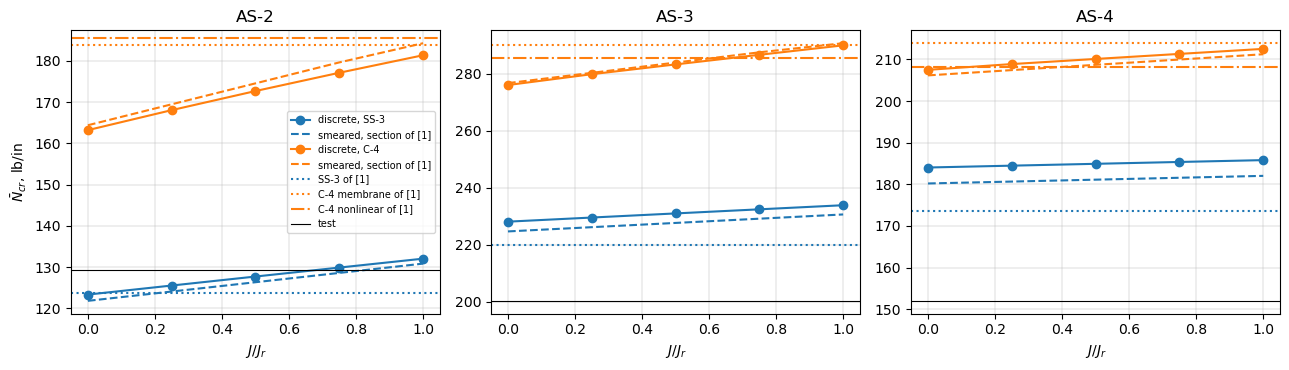

In [5]:
t0 = time.time()
RES = {(s, bc, f): run(s, bc, f, LEVELS[-1]) for s in shells for bc in ('SS', 'CC') for f in FJ}
print('%.0f s' % (time.time() - t0))
rows = []
for s in shells:
    P = TABLE2[s]
    for bc in ('SS', 'CC'):
        for f in FJ:
            N, modes = RES[(s, bc, f)][:2]
            ref = sm(s, f*shells[s]['Jr'], section='P', ends=bc)[0]
            row = [s, 'SS-3' if bc == 'SS' else 'C-4', f, '%.1f (%d, %d)' % (N, *modes[0][1:3]), '%.1f' % ref,
                   '**%+.1f %%**' % pct(N, ref)]
            if bc == 'SS':
                row += ['%+.1f %%' % pct(N, P[0]), '-', '-']
            else:
                row += ['-', '%+.1f %%' % pct(N, P[1]), '%+.1f %%' % pct(N, P[2])]
            row += ['%+.1f %%' % pct(N, P[3])]
            rows.append(row)
table(['shell', 'ends', 'J/J_r', 'discrete N, lb/in (m, n)', 'smeared, same strip', 'gap', 'vs SS-3 of [1]',
       'vs C-4 membrane', 'vs C-4 nonlinear', 'vs test'], rows)

# the factor f for which the discrete model gives each published value (linear interpolation)
rows = []
for s in shells:
    P = TABLE2[s]
    out = [s]
    for bc, target in (('SS', P[0]), ('CC', P[1]), ('CC', P[2])):
        Ns = np.array([RES[(s, bc, f)][0] for f in FJ])
        out.append('%.2f' % np.interp(target, Ns, FJ) if Ns[0] <= target <= Ns[-1] else
                   ('< 0' if target < Ns[0] else '> 1'))
    rows.append(out)
table(['shell', 'J/J_r for SS-3 of [1]', 'J/J_r for C-4 membrane of [1]', 'J/J_r for C-4 nonlinear of [1]'], rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, s in zip(axes, shells):
    P = TABLE2[s]
    for bc, c in (('SS', 'C0'), ('CC', 'C1')):
        ax.plot(FJ, [RES[(s, bc, f)][0] for f in FJ], c + 'o-', label='discrete, %s' % ('SS-3' if bc == 'SS' else 'C-4'))
        ax.plot(FJ, [sm(s, f*shells[s]['Jr'], ends=bc)[0] for f in FJ], c + '--',
                label='smeared, section of [1]')
    ax.axhline(P[0], color='C0', ls=':', label='SS-3 of [1]')
    ax.axhline(P[1], color='C1', ls=':', label='C-4 membrane of [1]')
    ax.axhline(P[2], color='C1', ls='-.', label='C-4 nonlinear of [1]')
    ax.axhline(P[3], color='k', ls='-', lw=0.8, label='test')
    ax.set_xlabel('$J/J_r$')
    ax.set_title(s)
    ax.grid(True, lw=0.3)
axes[0].set_ylabel(r'$\bar{N}_{cr}$, lb/in')
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Clamped ends with the linear static pre-buckling state

`bu.buckling_clamped`: $x = 0$ clamped, $x = L$ clamped with a uniform
shortening prescribed on skin and blades (the platens of the test rig), the
pre-buckling state the linear static solution, which contains the bending
of the skin near the ends that the end rings cause (the end rings of [1]
hold the radial expansion). It is the linear counterpart of the "nonlinear
C-4" column of [1]; level $(16, 8, 4)$.

In [6]:
t0 = time.time()
CLAMPED = {}
for s in shells:
    sh = shells[s]
    for f in (0., 1.):
        P, modes = bu.buckling_clamped(sh['R'], sh['t'], L, E, NU, sh['ts'], sh['Hs'], 'external', *LEVELS[1],
                                       nstiff=NS, blade_D66_factor=f*sh['Jr']/sh['Jp'])[:2]
        CLAMPED[(s, f)] = (P/(2*np.pi*sh['R']), modes[0][1:3])
print('%.0f s' % (time.time() - t0))
rows = []
for s in shells:
    P = TABLE2[s]
    for f in (0., 1.):
        N, mn = CLAMPED[(s, f)]
        rows.append([s, f, '%.1f %s' % (N, mn), '%+.1f %%' % pct(N, RES[(s, 'CC', f)][0]),
                     '%+.1f %%' % pct(N, P[1]), '%+.1f %%' % pct(N, P[2]), '%+.1f %%' % pct(N, P[3])])
table(['shell', 'J/J_r', 'N, lb/in (m, n)', 'vs membrane C-4 (discrete)', 'vs C-4 membrane of [1]',
       'vs C-4 nonlinear of [1]', 'vs test'], rows)

182 s


| shell | J/J_r | N, lb/in (m, n) | vs membrane C-4 (discrete) | vs C-4 membrane of [1] | vs C-4 nonlinear of [1] | vs test |
|---|---|---|---|---|---|---|
| AS-2 | 0.0 | 163.7 (2, 15) | +0.3 % | -10.9 % | -11.8 % | +26.7 % |
| AS-2 | 1.0 | 181.9 (2, 15) | +0.3 % | -1.0 % | -2.0 % | +40.8 % |
| AS-3 | 0.0 | 276.8 (3, 15) | +0.3 % | -4.6 % | -3.1 % | +38.2 % |
| AS-3 | 1.0 | 290.9 (3, 14) | +0.3 % | +0.2 % | +1.8 % | +45.2 % |
| AS-4 | 0.0 | 207.6 (3, 16) | +0.0 % | -3.0 % | -0.3 % | +36.5 % |
| AS-4 | 1.0 | 212.7 (3, 15) | +0.1 % | -0.6 % | +2.2 % | +39.9 % |

## Every published value against the models ($J = J_r$)

| shell | value of [1] | lb/in | smeared, section of [1] | vs [1] | discrete | vs [1] |
|---|---|---|---|---|---|---|
| AS-2 | SS-3 | 123.8 | 130.8 | +5.7 % | 132.0 | +6.7 % |
| AS-2 | C-4 membrane | 183.8 | 184.3 | +0.3 % | 181.4 | -1.3 % |
| AS-2 | C-4 nonlinear | 185.6 | - | - | 181.9 (linear static) | -2.0 % |
| AS-2 | test | 129.2 | - | - | 181.9 (C-4, linear static) | +40.8 % |
| AS-3 | SS-3 | 219.8 | 230.6 | +4.9 % | 233.9 | +6.4 % |
| AS-3 | C-4 membrane | 290.2 | 290.7 | +0.2 % | 290.0 | -0.1 % |
| AS-3 | C-4 nonlinear | 285.7 | - | - | 290.9 (linear static) | +1.8 % |
| AS-3 | test | 200.3 | - | - | 290.9 (C-4, linear static) | +45.2 % |
| AS-4 | SS-3 | 173.5 | 182.0 | +4.9 % | 185.8 | +7.1 % |
| AS-4 | C-4 membrane | 213.9 | 211.2 | -1.2 % | 212.5 | -0.6 % |
| AS-4 | C-4 nonlinear | 208.1 | - | - | 212.7 (linear static) | +2.2 % |
| AS-4 | test | 152.0 | - | - | 212.7 (C-4, linear static) | +39.9 % |

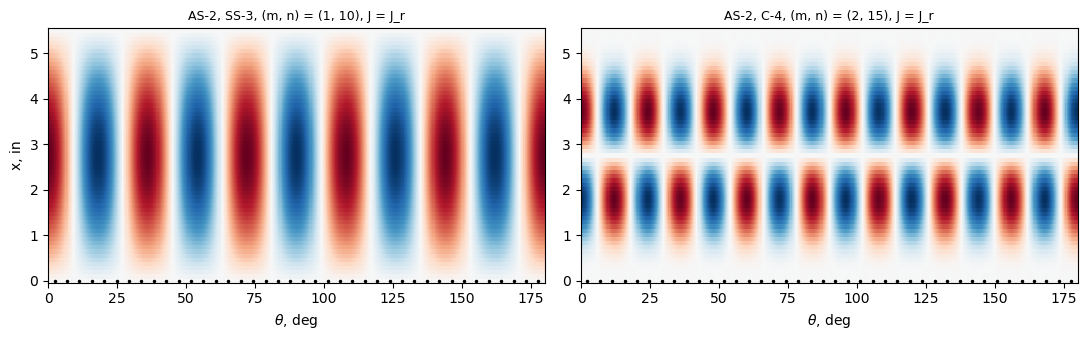

In [7]:
rows = []
for s in shells:
    P = TABLE2[s]
    Nss, Ncc, Ncl = RES[(s, 'SS', 1.)][0], RES[(s, 'CC', 1.)][0], CLAMPED[(s, 1.)][0]
    rows.append([s, 'SS-3', P[0], '%.1f' % SM[(s, 'SS', 1.)][0], '%+.1f %%' % pct(SM[(s, 'SS', 1.)][0], P[0]),
                 '%.1f' % Nss, '%+.1f %%' % pct(Nss, P[0])])
    rows.append([s, 'C-4 membrane', P[1], '%.1f' % SM[(s, 'CC', 1.)][0], '%+.1f %%' % pct(SM[(s, 'CC', 1.)][0], P[1]),
                 '%.1f' % Ncc, '%+.1f %%' % pct(Ncc, P[1])])
    rows.append([s, 'C-4 nonlinear', P[2], '-', '-', '%.1f (linear static)' % Ncl, '%+.1f %%' % pct(Ncl, P[2])])
    rows.append([s, 'test', P[3], '-', '-', '%.1f (C-4, linear static)' % Ncl, '%+.1f %%' % pct(Ncl, P[3])])
table(['shell', 'value of [1]', 'lb/in', 'smeared, section of [1]', 'vs [1]', 'discrete', 'vs [1]'], rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, bc in zip(axes, ('SS', 'CC')):
    N, modes, N1, md_, skin = RES[('AS-2', bc, 1.)][:5]
    plot_mode(ax, md_, modes[0][3], skin, shells['AS-2']['R'],
              'AS-2, %s, (m, n) = (%d, %d), J = J_r' % ('SS-3' if bc == 'SS' else 'C-4', *modes[0][1:3]), NS)
axes[0].set_ylabel('x, in')
plt.tight_layout()
plt.show()

## Discussion

- **Input.** The rectangle $t_s \times h_s$ from $A$ and $I$ of Table 1
  reproduces the printed eccentricity within 0.7 %, so the stringers are read
  as Singer, Arbocz and Babcock read them, up to the non-rectangular shapes
  they mention. With the section of Table 1, the clamped smeared theory (Ritz
  with the functions (A5) of [3]) and $J = J_r$ reproduces the C-4 membrane
  loads of [1] within -1.2 to +0.3 % (AS-2 184.3, AS-3 290.7, AS-4 211.2
  lb/in against 183.8, 290.2, 213.9); the $J$ that reproduces them exactly is
  0.97, 0.96 and 1.52 $J_r$. The C-4 column of [1] is therefore consistent
  with stringers that twist with the Saint-Venant constant of their
  rectangle.
- **One $J$ does not fit both columns of [1].** Equation (15) of [2] with
  $J = J_r$ is +5.7, +4.9 and +4.9 % above the SS-3 loads of [1]; with $J =
  0$ it is still +2.2 and +3.9 % above them for AS-3 and AS-4 (AS-2 -1.6 %;
  the $J$ that fits AS-2 is 0.22 $J_r$). The SS-3 column of [1] is thus lower
  than equation (15) for any non-negative $J$ by 2 to 4 % for AS-3 and AS-4:
  the difference is not the torsion constant alone but the theory of [4],
  which [1] used for SS-3 and which is not read here (its kinematics and its
  stringer model may differ from those of [2]). The C-4 values, from another
  analysis, agree with [2] and [3]. The question is open; the SS-3 values of
  [1] are compared, not used to choose $J$.
- **Sensitivity to $J$.** From $J = 0$ to $J = J_r$ the clamped load rises by
  11 % (AS-2), 5 % (AS-3) and 2.4 % (AS-4), the simply supported one by 7,
  2.5 and 1 %: the flat stringer of AS-2, the tallest, twists most, and the
  short clamped buckles (two to four axial half-waves, 14 to 16
  circumferential waves) twist the stringers more than the SS-3 mode of one
  half-wave. With $J = 0$ the discrete model is 3 to 11 % below the C-4
  loads of [1]; with $J_r$ within -1.3 to -0.1 %. The plate strip as it is, with
  18 to 53 times the twisting stiffness $G J_r$, would be far outside this
  range: a flat stringer is modelled by a blade normal to the skin only with
  the scaled $D_{66}$.
- **Discreteness gap.** The discrete model buckles in the general modes of
  the smeared theory, (1, 9 to 10) simply supported and (2 to 4, 14 to 16)
  clamped, 1.0 to 2.5 % below equation (15) or the clamped Ritz solution for
  the same plate strip and the same $J$: the gap of the Weller and Singer
  shells AS-34 and AS-35 (`weller1977_blade_cylinder_buckling.ipynb`, -1.7 %
  at $b/\sqrt{Rh} = 1.6$; 1.5 to 1.8 here). It grows with $J$
  for the clamped AS-2 (-1.6 to -2.5 %), where the stringers twist most.
- **Pre-buckling state.** The linear static pre-buckling state of the clamped
  shell (end rings holding the radial expansion) raises the discrete load by
  0.0 to 0.3 %; [1] finds with the nonlinear one +1.0 % (AS-2) and -1.5 and
  -2.7 % (AS-3, AS-4). The discrete model with the linear static state is
  -2.0, +1.8 and +2.2 % from the nonlinear C-4 loads of [1]: as [1]
  concludes (p. 72), the pre-buckling deformation is a small effect for
  these shells.
- **Tests.** The tests are at 0.70 to 0.73 of the nonlinear C-4 loads of [1]
  (Table 2) and 28 to 31 % below the clamped discrete model ($J = J_r$,
  linear static state); they are close to the SS-3 loads (AS-2 +4.4 %, AS-3
  and AS-4 -8.9 and -12.4 %), whereas the authors judged the end rings rigid (p. 72) and measured initial
  imperfections of about one wall thickness, with a strong pre-buckling
  growth of one axial half-wave and nine circumferential waves (p. 74), the
  shape of the simply supported mode (1, 9 to 10), not of the clamped modes
  (2 to 4, 14 to 16). Their "linearity" (test over clamped theory) is lower
  than that of the ring-stiffened shells of the same paper (0.70 to 1.12,
  Table 2).
- **The bfsccylinder implementation of this case**
  (`bfsccylinder/notebooks/singer1971_stiffened_cylinder_buckling.ipynb`:
  one stringer pitch with cyclic symmetry, `BFSCCylinderSanders` skin and
  `BFSCPlate2D` stringer, the same strips and $J$) gives the same modes
  (with the linear static state (4, 14) for AS-3) and agrees within 0.6 %,
  0.1 to 0.2 % higher simply supported and 0.4 to 0.6 % higher clamped:
  with $J = J_r$, SS-3 132.2, 234.1, 186.0 lb/in (here 132.0, 233.9,
  185.8), C-4 membrane 182.2, 291.2, 213.5 (here 181.4, 290.0, 212.5),
  linear static state 182.8, 292.1, 213.9 (here 181.9, 290.9, 212.7); with
  $J = 0$, C-4 164.0, 277.4, 208.6 (here 163.2, 276.1, 207.5). Its gaps are
  -1.1 to -1.4 % (SS-3) and -0.5 to -2.0 % (C-4).